# Yambda-50M: initial analysis, organic vs recommended listening

**Goal of this notebook:** get a first, honest picture of how the *organic* stream (`is_organic = 1`) and the
*recommended* stream (`is_organic = 0`) differ, using only what the data offers (anonymous IDs, artist mapping,
played percentage, time). It prepares the ground for 2-3 course methods on one question.

Sections
1. Load and set up
2. Sanity check of `is_organic`
3. Users: how much data per stream?
4. Discovery and repeat listening (why raw comparisons mislead)
5. Fair diversity comparison (same user, same number of *new* tracks)
6. Artist concentration
7. Sessions as baskets
8. Preview of RQ2: user similarity (Jaccard) per stream
9. Summary

**Conventions:** a *real listen* is a listen with `played_ratio_pct >= REAL_PCT`. Everything with the same
user is compared on equal-sized samples (`N_TRACKS` distinct tracks per stream).
Run time: a few minutes, memory about 4-6 GB.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from scipy import stats
from scipy.sparse import csr_matrix

# ---- parameters (change here, then Run All) ----
REAL_PCT = 50          # a "real listen" has at least this % played
N_TRACKS = 100         # distinct tracks per user and stream in the fair comparison
SESSION_GAP_S = 30 * 60
SEED = 42
N_USERS_JACCARD = 1000

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COL = {"organic": "#2a9d8f", "recommended": "#e76f51"}   # one colour per stream, used everywhere

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Could not find data/raw/yambda above " + str(Path.cwd()))
    ROOT = ROOT.parent
DATA = ROOT / "data" / "raw" / "yambda"
print("project root:", ROOT)
summary = {}   # key numbers collected along the way, printed in section 9

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. Load
Only listens are used (likes etc. are rare). The file is sorted by `(uid, timestamp)`.

In [2]:
t0 = time.time()
cols = ["uid", "item_id", "timestamp", "is_organic", "played_ratio_pct", "event_type"]
df = pq.read_table(DATA / "flat/50m/multi_event.parquet", columns=cols).to_pandas()
df = df[df["event_type"] == "listen"].drop(columns="event_type").reset_index(drop=True)
df["is_organic"] = df["is_organic"].astype("int8")
df["played_ratio_pct"] = df["played_ratio_pct"].astype("float32")

# first artist of every item (99.98% of listens have one); -1 = no artist
art = pd.read_parquet(DATA / "artist_item_mapping.parquet").drop_duplicates("item_id")
item_art = np.full(int(df["item_id"].max()) + 1, -1, dtype=np.int32)
ids = art["item_id"].to_numpy()
ok = ids < len(item_art)
item_art[ids[ok]] = art["artist_id"].to_numpy()[ok]
df["artist"] = item_art[df["item_id"].to_numpy()]

new_user = (df["uid"] != df["uid"].shift()).to_numpy()
df["uidx"] = (np.cumsum(new_user) - 1).astype(np.int32)   # compact user index 0..n-1
n_users = int(df["uidx"].iloc[-1]) + 1
print(f"{len(df):,} listens, {n_users:,} users, {df['item_id'].nunique():,} tracks, "
      f"{(df['artist'] < 0).mean():.2%} without artist  ({time.time() - t0:.0f} s)")
df.head()

46,467,212 listens, 9,238 users, 877,168 tracks, 0.02% without artist  (6 s)


,uid,item_id,timestamp,is_organic,played_ratio_pct,artist,uidx
0,100,8326270,39420,0,100.0,714356,0
1,100,1441281,39420,0,100.0,1043457,0
2,100,286361,39625,0,100.0,94924,0
3,100,732449,40110,0,100.0,94924,0
4,100,3397170,40360,0,46.0,997338,0


## 2. Sanity check of `is_organic`
The dataset card says `1 = organic`, `0 = recommendation-driven`. If so, the two streams should *behave* differently.
Below: distribution of the played percentage per stream, and a table of skip/finish rates.

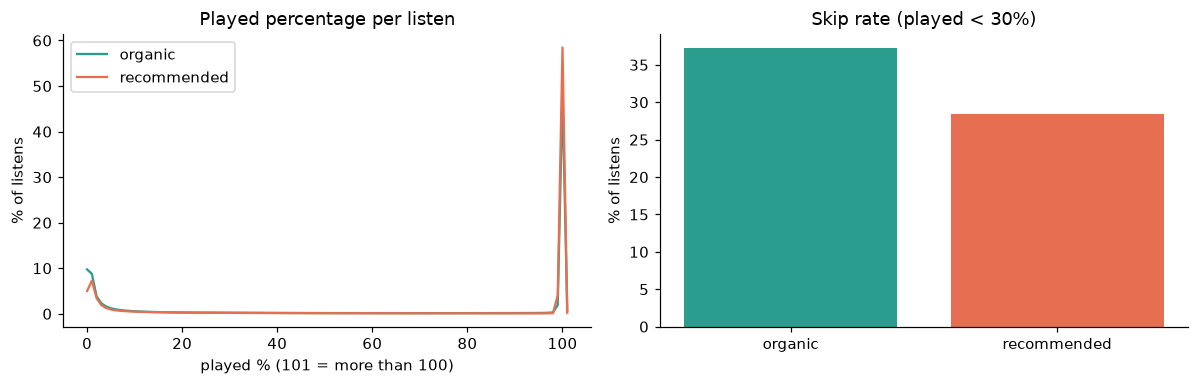

,listens,share,played < 30%,played >= 50%,played >= 80%,mean played %
stream,,,,,,
organic,"24,003,657",51.7%,37.2%,58.8%,54.3%,60.2
recommended,"22,463,555",48.3%,28.5%,68.2%,64.8%,69.6


In [3]:
org = df["is_organic"].to_numpy()
ratio = df["played_ratio_pct"].to_numpy()
clip = np.clip(ratio, 0, 101).astype(int)
dist = {s: np.bincount(clip[org == v], minlength=102) / (org == v).sum()
        for s, v in [("organic", 1), ("recommended", 0)]}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s in dist:
    ax[0].plot(range(102), dist[s] * 100, label=s, color=COL[s])
ax[0].set(title="Played percentage per listen", xlabel="played % (101 = more than 100)", ylabel="% of listens")
ax[0].legend()
rows = []
for s, v in [("organic", 1), ("recommended", 0)]:
    r = ratio[org == v]
    rows.append({"stream": s, "listens": len(r), "share": len(r) / len(org),
                 "played < 30%": (r < 30).mean(), f"played >= {REAL_PCT}%": (r >= REAL_PCT).mean(),
                 "played >= 80%": (r >= 80).mean(), "mean played %": r.mean()})
tab = pd.DataFrame(rows).set_index("stream")
ax[1].bar(tab.index, tab["played < 30%"] * 100, color=[COL[s] for s in tab.index])
ax[1].set(title="Skip rate (played < 30%)", ylabel="% of listens")
plt.tight_layout(); plt.show()
summary["organic share of listens"] = tab.loc["organic", "share"]
tab.style.format({"listens": "{:,.0f}", "share": "{:.1%}", "played < 30%": "{:.1%}",
                  f"played >= {REAL_PCT}%": "{:.1%}", "played >= 80%": "{:.1%}", "mean played %": "{:.1f}"})

## 3. Users
How many listens does each user have in each stream? This decides who can be included in per-user comparisons.

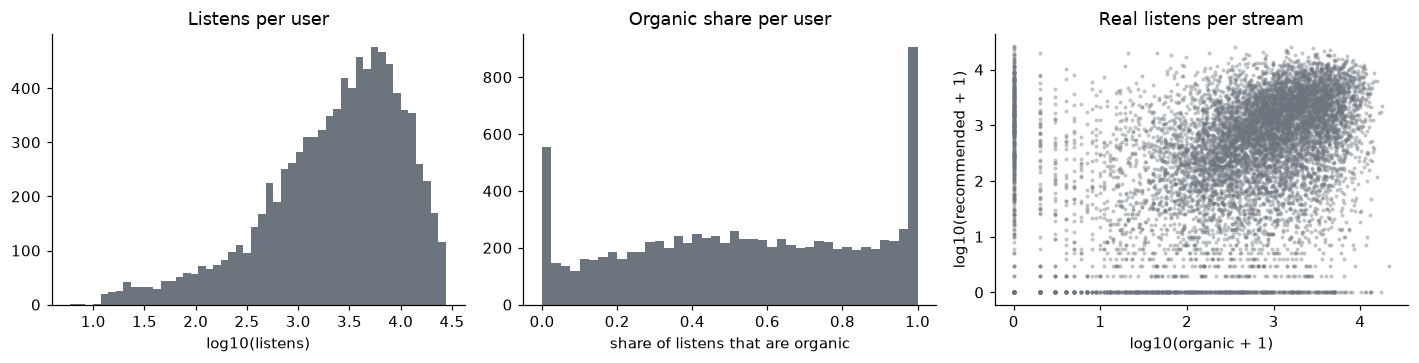

users with >= 100 real listens in both streams: 5,930 of 9,238


In [4]:
real_mask = ratio >= REAL_PCT
uidx = df["uidx"].to_numpy()
tot = np.bincount(uidx, minlength=n_users)
real_org = np.bincount(uidx[real_mask & (org == 1)], minlength=n_users)
real_rec = np.bincount(uidx[real_mask & (org == 0)], minlength=n_users)
share_org = np.bincount(uidx[org == 1], minlength=n_users) / tot

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(np.log10(tot), bins=50, color="#6c757d"); ax[0].set(title="Listens per user", xlabel="log10(listens)")
ax[1].hist(share_org, bins=40, color="#6c757d"); ax[1].set(title="Organic share per user", xlabel="share of listens that are organic")
ax[2].scatter(np.log10(real_org + 1), np.log10(real_rec + 1), s=3, alpha=0.3, color="#6c757d")
ax[2].set(title="Real listens per stream", xlabel="log10(organic + 1)", ylabel="log10(recommended + 1)")
plt.tight_layout(); plt.show()
both = (real_org >= N_TRACKS) & (real_rec >= N_TRACKS)
print(f"users with >= {N_TRACKS} real listens in both streams: {both.sum():,} of {n_users:,}")

## 4. Discovery and repeat listening
A track played organically is often one the user *already knows*. Recommended listens are more often *new* tracks.
This matters: counting every listen would compare "repeating favourites" with "trying new things".

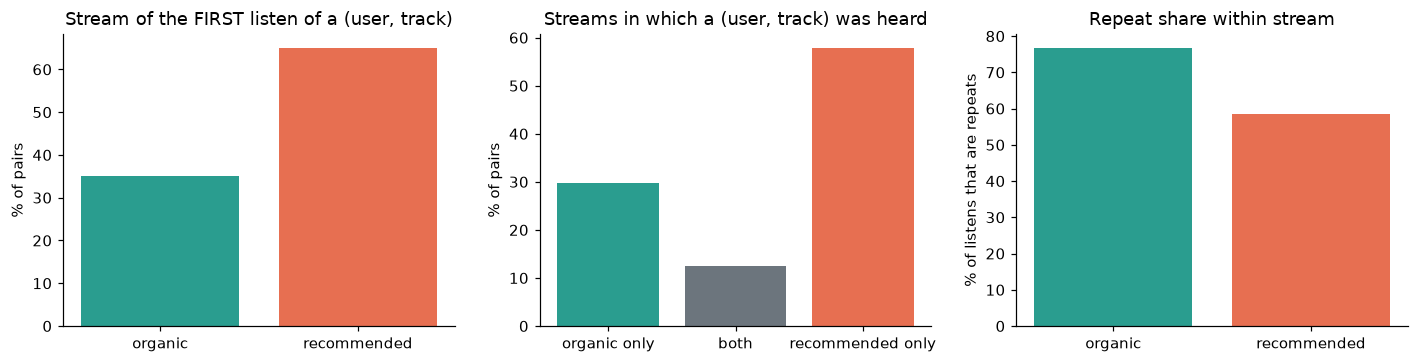

(user, track) pairs: 13,268,889  ->  3.50 listens per pair


In [5]:
key = df["uid"].to_numpy().astype(np.int64) * (1 << 32) + df["item_id"].to_numpy()
uniq, first_idx, inv = np.unique(key, return_index=True, return_inverse=True)
n_pairs = len(uniq)
first_org = org[first_idx]
has_org = np.bincount(inv, weights=(org == 1), minlength=n_pairs) > 0
has_rec = np.bincount(inv, weights=(org == 0), minlength=n_pairs) > 0
item_users = np.bincount((uniq & 0xFFFFFFFF).astype(np.int64))   # distinct users per track (popularity)

# repeat share inside each stream: listens that are not the first play of that (user, track) in that stream
rep = {}
for s, v in [("organic", 1), ("recommended", 0)]:
    k = key[org == v]
    rep[s] = 1 - len(np.unique(k)) / len(k)
del inv

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
fs = [first_org.mean(), 1 - first_org.mean()]
ax[0].bar(["organic", "recommended"], np.array(fs) * 100, color=[COL["organic"], COL["recommended"]])
ax[0].set(title="Stream of the FIRST listen of a (user, track)", ylabel="% of pairs")
cat = {"organic only": (has_org & ~has_rec).mean(), "both": (has_org & has_rec).mean(),
       "recommended only": (~has_org & has_rec).mean()}
ax[1].bar(cat.keys(), np.array(list(cat.values())) * 100, color=[COL["organic"], "#6c757d", COL["recommended"]])
ax[1].set(title="Streams in which a (user, track) was heard", ylabel="% of pairs")
ax[2].bar(rep.keys(), np.array(list(rep.values())) * 100, color=[COL[s] for s in rep])
ax[2].set(title="Repeat share within stream", ylabel="% of listens that are repeats")
plt.tight_layout(); plt.show()
print(f"(user, track) pairs: {n_pairs:,}  ->  {len(df) / n_pairs:.2f} listens per pair")
summary["pairs first discovered via recommendation"] = 1 - first_org.mean()
summary["repeat share organic"] = rep["organic"]
summary["repeat share recommended"] = rep["recommended"]

**Design decision (to discuss):** a track found through a recommendation and replayed later counts as *organic*
in the second case. For fair comparisons we therefore compare **distinct tracks** (first play of each track within a stream),
not raw listens.

In [6]:
r = df.loc[real_mask & (df["artist"] >= 0), ["uidx", "item_id", "is_organic", "artist"]]
k3 = (r["uidx"].to_numpy().astype(np.int64) << 33) | (r["item_id"].to_numpy().astype(np.int64) << 1) | r["is_organic"].to_numpy()
_, fi = np.unique(k3, return_index=True)
u = r.iloc[np.sort(fi)].copy()                        # first real listen of each (user, track, stream), time ordered
u["rank"] = u.groupby(["uidx", "is_organic"]).cumcount()
cnt = u.groupby(["uidx", "is_organic"]).size().unstack(fill_value=0)
eligible = cnt.index[(cnt[0] >= N_TRACKS) & (cnt[1] >= N_TRACKS)]
sample = u[(u["rank"] < N_TRACKS) & u["uidx"].isin(eligible)].copy()
sample["stream"] = np.where(sample["is_organic"] == 1, "organic", "recommended")
sample["log_users"] = np.log10(item_users[sample["item_id"].to_numpy()].clip(min=1))
del r, k3, u
print(f"{len(eligible):,} users have >= {N_TRACKS} distinct real tracks in both streams; "
      f"sample = {len(sample):,} (user, track) rows")
summary["users in fair comparison"] = len(eligible)

5,537 users have >= 100 distinct real tracks in both streams; sample = 1,107,400 (user, track) rows


## 5. Fair diversity comparison
For every eligible user: take their first `N_TRACKS` distinct real tracks in each stream and compare

* **distinct artists** among those tracks (more = broader),
* **artist entropy** in bits (higher = broader and more even),
* **mainstreamness**: mean log10 of the number of users who played each track (higher = more popular tracks).

Each user is their own control, so we use paired tests (Wilcoxon signed-rank). This is an *association*, not proof of
causation: the recommender and the user influence each other.

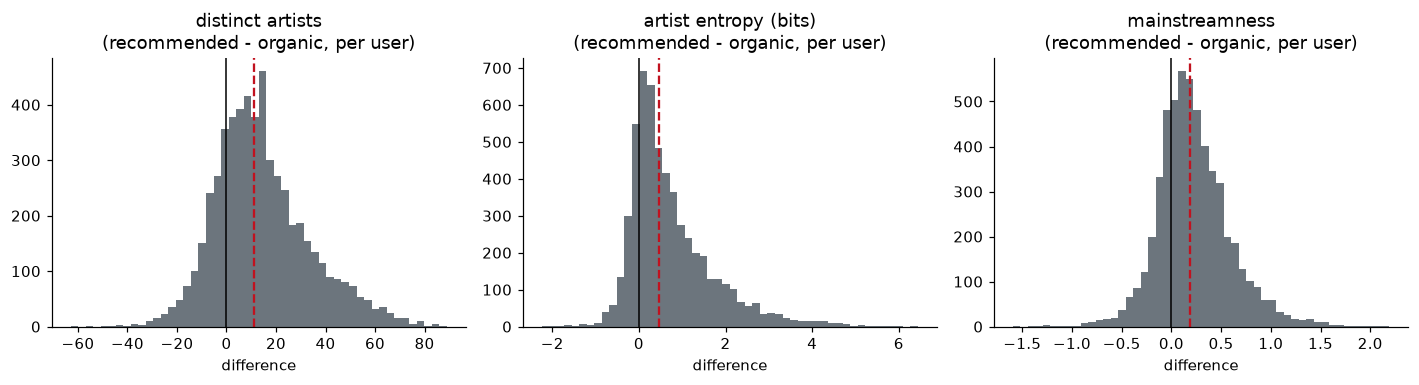

,organic median,recommended median,median difference,users with recommended > organic,Wilcoxon p
metric,,,,,
distinct artists,65.00,78.00,+11.00,75.7%,0.0e+00
artist entropy (bits),5.60,6.13,+0.48,80.7%,0.0e+00
mainstreamness,2.29,2.51,+0.19,74.2%,0.0e+00


In [7]:
g = sample.groupby(["uidx", "stream", "artist"]).size()
p = g / g.groupby(level=[0, 1]).transform("sum")
metrics = pd.DataFrame({
    "distinct artists": g.groupby(level=[0, 1]).size(),
    "artist entropy (bits)": -(p * np.log2(p)).groupby(level=[0, 1]).sum(),
    "mainstreamness": sample.groupby(["uidx", "stream"])["log_users"].mean(),
})
wide = metrics.unstack("stream")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
rows = []
for a, m in zip(ax, metrics.columns):
    o, rc = wide[m]["organic"], wide[m]["recommended"]
    d = rc - o
    a.hist(d, bins=50, color="#6c757d")
    a.axvline(0, color="k", lw=1); a.axvline(d.median(), color="#c1121f", lw=1.5, ls="--")
    a.set(title=f"{m}\n(recommended - organic, per user)", xlabel="difference")
    stat, pv = stats.wilcoxon(d)
    rows.append({"metric": m, "organic median": o.median(), "recommended median": rc.median(),
                 "median difference": d.median(), "users with recommended > organic": (d > 0).mean(), "Wilcoxon p": pv})
plt.tight_layout(); plt.show()
res = pd.DataFrame(rows).set_index("metric")
for m in res.index:
    summary[f"{m}: median (recommended - organic)"] = res.loc[m, "median difference"]
res.style.format({"organic median": "{:.2f}", "recommended median": "{:.2f}", "median difference": "{:+.2f}",
                  "users with recommended > organic": "{:.1%}", "Wilcoxon p": "{:.1e}"})

## 6. Artist concentration
How unevenly are artists spread over users in each stream? Lorenz curve of *users per artist* (on the same equal-sized
samples) and the Gini coefficient. A more unequal curve means a few artists are shared by many users.

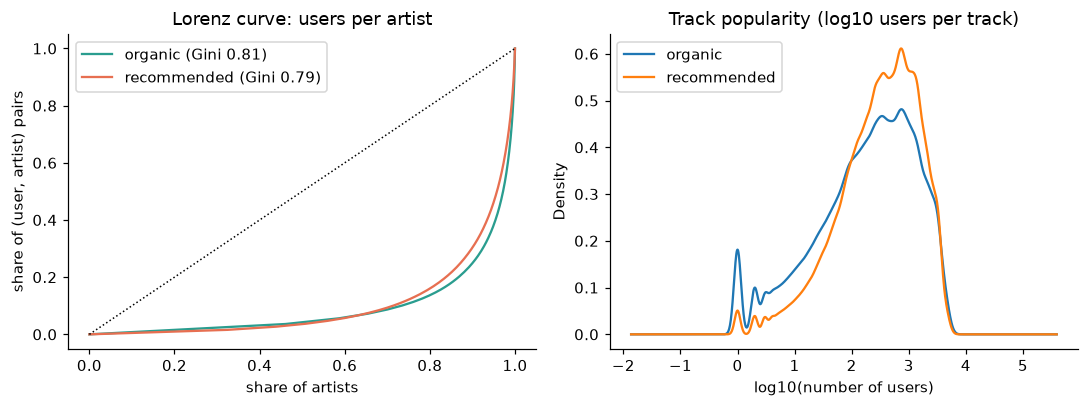

,distinct artists,Gini,top 1% artists' share
organic,26350.0,0.810535,0.309606
recommended,19739.0,0.791955,0.228559


In [8]:
def gini(x):
    x = np.sort(x.astype(float)); n = len(x)
    return (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
conc = {}
for s in ["organic", "recommended"]:
    users_per_artist = (sample[sample["stream"] == s].drop_duplicates(["uidx", "artist"])
                        .groupby("artist").size().sort_values().to_numpy())
    cum = np.cumsum(users_per_artist) / users_per_artist.sum()
    ax[0].plot(np.linspace(0, 1, len(cum)), cum, color=COL[s], label=f"{s} (Gini {gini(users_per_artist):.2f})")
    top1 = np.sort(users_per_artist)[::-1][: max(1, len(users_per_artist) // 100)].sum() / users_per_artist.sum()
    conc[s] = {"distinct artists": len(users_per_artist), "Gini": gini(users_per_artist), "top 1% artists' share": top1}
ax[0].plot([0, 1], [0, 1], "k:", lw=1)
ax[0].set(title="Lorenz curve: users per artist", xlabel="share of artists", ylabel="share of (user, artist) pairs"); ax[0].legend()
sample.groupby("stream")["log_users"].plot(kind="kde", ax=ax[1], legend=True, color=None)
ax[1].set(title="Track popularity (log10 users per track)", xlabel="log10(number of users)")
plt.tight_layout(); plt.show()
pd.DataFrame(conc).T

## 7. Sessions as baskets
For frequent itemsets we need baskets. A session is a run of a user's listens with gaps of at most 30 minutes.
We count real listens per stream inside each session.

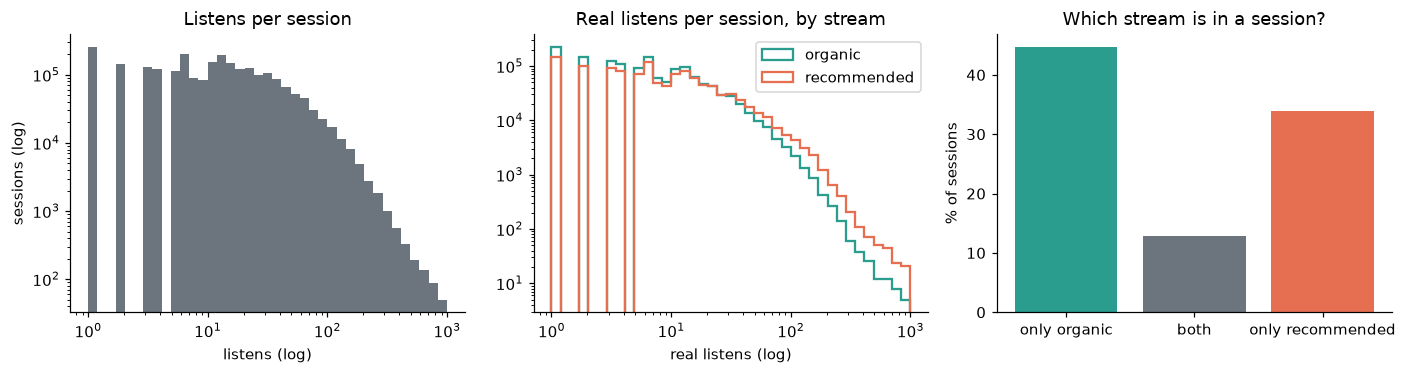

2,452,609 sessions, median 10 listens, 1.9% have > 100 listens
candidate pairs (sum k(k-1)/2): organic 266,647,419  recommended 482,527,888


In [9]:
ts = df["timestamp"].to_numpy().astype(np.int64)
new_sess = np.empty(len(df), dtype=bool)
new_sess[0] = True
new_sess[1:] = new_user[1:] | ((ts[1:] - ts[:-1]) > SESSION_GAP_S)
sid = np.cumsum(new_sess) - 1
n_sess = int(sid[-1]) + 1
size = np.bincount(sid, minlength=n_sess)
s_org = np.bincount(sid[real_mask & (org == 1)], minlength=n_sess)
s_rec = np.bincount(sid[real_mask & (org == 0)], minlength=n_sess)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
bins = np.logspace(0, 3, 40)
ax[0].hist(size, bins=bins, color="#6c757d"); ax[0].set_xscale("log"); ax[0].set_yscale("log")
ax[0].set(title="Listens per session", xlabel="listens (log)", ylabel="sessions (log)")
for s, v in [("organic", s_org), ("recommended", s_rec)]:
    ax[1].hist(v[v > 0], bins=bins, histtype="step", color=COL[s], label=s, lw=1.5)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].legend()
ax[1].set(title="Real listens per session, by stream", xlabel="real listens (log)")
kinds = {"only organic": ((s_org > 0) & (s_rec == 0)).mean(), "both": ((s_org > 0) & (s_rec > 0)).mean(),
         "only recommended": ((s_org == 0) & (s_rec > 0)).mean()}
ax[2].bar(kinds.keys(), np.array(list(kinds.values())) * 100, color=[COL["organic"], "#6c757d", COL["recommended"]])
ax[2].set(title="Which stream is in a session?", ylabel="% of sessions")
plt.tight_layout(); plt.show()
pairs = lambda k: int((k.astype(np.int64) * (k - 1) // 2).sum())
print(f"{n_sess:,} sessions, median {np.median(size):.0f} listens, {(size > 100).mean():.1%} have > 100 listens")
print(f"candidate pairs (sum k(k-1)/2): organic {pairs(s_org):,}  recommended {pairs(s_rec):,}")
summary["sessions"] = n_sess
summary["sessions with both streams"] = kinds["both"]

## 8. Preview of RQ2: are users more alike in one stream?
For a random sample of eligible users, build each user's **artist set** from their `N_TRACKS` distinct tracks per stream and
compute exact pairwise Jaccard similarity. This is the exact baseline that MinHash/LSH will later approximate.
Also: how similar is a user's own organic set to their own recommended set?

*Caveat:* Jaccard depends on set size, and artist sets differ in size between streams (see section 5). Treat this as a preview.

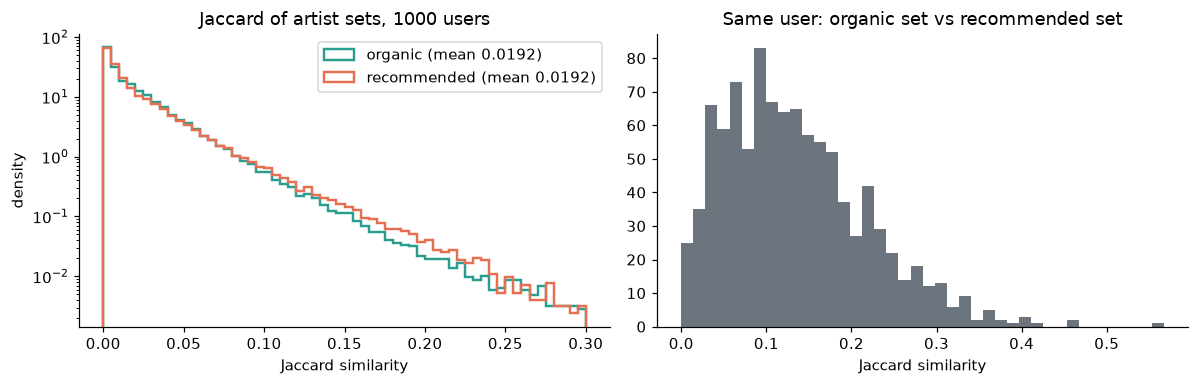

{'organic': {'mean': 0.01915, 'p99': 0.1171}, 'recommended': {'mean': 0.01917, 'p99': 0.1277}}


In [10]:
pick = rng.choice(eligible.to_numpy(), size=min(N_USERS_JACCARD, len(eligible)), replace=False)
sub = sample[sample["uidx"].isin(pick)].drop_duplicates(["uidx", "stream", "artist"])
user_pos = {u_: i for i, u_ in enumerate(pick)}
art_codes, art_uni = pd.factorize(sub["artist"])
mats = {}
for s in ["organic", "recommended"]:
    m = (sub["stream"] == s).to_numpy()
    rows_ = sub.loc[m, "uidx"].map(user_pos).to_numpy()
    mats[s] = csr_matrix((np.ones(m.sum(), dtype=np.float32), (rows_, art_codes[m])), shape=(len(pick), len(art_uni)))

def pairwise_jaccard(X):
    inter = (X @ X.T).toarray()
    sz = np.asarray(X.sum(axis=1)).ravel()
    union = sz[:, None] + sz[None, :] - inter
    j = inter / np.maximum(union, 1)
    return j[np.triu_indices(len(sz), k=1)]

J = {s: pairwise_jaccard(mats[s]) for s in mats}
inter_own = np.asarray(mats["organic"].multiply(mats["recommended"]).sum(axis=1)).ravel()
union_own = (np.asarray(mats["organic"].sum(axis=1)).ravel() + np.asarray(mats["recommended"].sum(axis=1)).ravel() - inter_own)
own = inter_own / union_own

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for s in J:
    ax[0].hist(J[s], bins=np.linspace(0, 0.3, 61), histtype="step", color=COL[s], lw=1.6, label=f"{s} (mean {J[s].mean():.4f})", density=True)
ax[0].set(title=f"Jaccard of artist sets, {len(pick)} users", xlabel="Jaccard similarity", ylabel="density"); ax[0].legend()
ax[0].set_yscale("log")
ax[1].hist(own, bins=40, color="#6c757d")
ax[1].set(title="Same user: organic set vs recommended set", xlabel="Jaccard similarity")
plt.tight_layout(); plt.show()
for s in J:
    summary[f"mean user-user Jaccard, {s}"] = J[s].mean()
summary["median own organic-vs-recommended Jaccard"] = float(np.median(own))
print({s: dict(mean=round(float(J[s].mean()), 5), p99=round(float(np.quantile(J[s], 0.99)), 4)) for s in J})

## 9. Summary

In [11]:
pd.Series(summary, name="value").to_frame().style.format(lambda v: f"{v:,.4f}" if isinstance(v, float) else f"{v:,}")

,value
organic share of listens,0.5166
pairs first discovered via recommendation,0.6498
repeat share organic,0.7670
repeat share recommended,0.5850
users in fair comparison,"5,537.0000"
distinct artists: median (recommended - organic),11.0000
artist entropy (bits): median (recommended - organic),0.4758
mainstreamness: median (recommended - organic),0.1864
sessions,"2,452,609.0000"
sessions with both streams,0.1287


### Notes for the team (fill in after discussing the figures)
* Is the `is_organic` coding plausible? (section 2 and 4)
* Do the fair comparisons in section 5 and 8 show narrowing, widening, or no clear difference?
* Which question and which 2-3 methods do we choose? Candidates: frequent itemsets on artist baskets (section 7),
  MinHash/LSH on artist sets (section 8), clustering or graph communities of users/artists.
* Open points: audio embeddings (not used yet), sensitivity to `REAL_PCT` (try 30 and 80) and `N_TRACKS`.